# Stage 3 - Phat hien cong dong & tien hoa cong dong trong mang hashtag TikTok dong

**Chuan bi:** tao Kaggle Dataset gom 2 file `video_hashtag_time.csv` + `stage3_dynamic_communities.py`, Add vao notebook.
Settings: **Internet = On** (de pip install). Accelerator: **None/CPU la du** (igraph/leidenalg chi chay CPU, GPU khong duoc dung).

| Buoc | Y nghia |
|---|---|
| TRAIN | Chon `gamma` (resolution) va `omega` (lien ket giua snapshot) tren 70% snapshot dau |
| EVALUATE | Chay 4 phuong phap tren toan bo snapshot, danh gia rieng train/test |

In [1]:
%cd /kaggle/working

!git clone https://github.com/ThaoTo2806/tittokSNA28.git


/kaggle/working
Cloning into 'tittokSNA28'...
remote: Enumerating objects: 177, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 177 (delta 2), reused 21 (delta 2), pack-reused 153 (from 1)
Receiving objects: 100% (177/177), 44.73 MiB | 22.43 MiB/s, done.
Resolving deltas: 100% (66/66), done.
Updating files: 100% (102/102), done.


In [2]:
%cd /kaggle/working/tittokSNA28
!pip install -q igraph leidenalg

/kaggle/working/tittokSNA28


In [3]:
import glob, os, shutil, sys
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50); pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 120)

csv = glob.glob('/kaggle/working/tittokSNA28/data/processed/temporal/video_hashtag_time.csv', recursive=True)
py = glob.glob('/kaggle/working/tittokSNA28/stage3_dynamic_communities.py', recursive=True)
assert csv and py, 'Chua Add dataset chua video_hashtag_time.csv va stage3_dynamic_communities.py'
DATA = csv[0]
WORK = '/kaggle/working'
OUT = f'{WORK}/stage3_output'
shutil.copy(py[0], WORK)
os.chdir(WORK)
print('DATA =', DATA)
print('OUT  =', OUT)

DATA = /kaggle/working/tittokSNA28/data/processed/temporal/video_hashtag_time.csv
OUT  = /kaggle/working/stage3_output


## 1. TRAIN - chon tham so tren snapshot train
Tieu chi: `score = 0.5 * (modularity_t + predictive_modularity_{t->t+1})` (chat luong hien tai + kha nang tong quat sang snapshot ke tiep).

In [4]:
!python stage3_dynamic_communities.py tune --input {DATA} --output {OUT}
display(pd.read_csv(f'{OUT}/tuning.csv').round(4))
print(open(f'{OUT}/tuning_result.json', encoding='utf-8').read())

[12:29:05] [TRAIN] Tune tren 7 snapshot train: 2026-01 -> 2026-07
[12:29:14]   leiden gamma=0.5   Q=0.7205 Q_next=0.4049 NMI_prev=0.4993 score=0.5627
[12:29:22]   leiden gamma=1.0   Q=0.7433 Q_next=0.4128 NMI_prev=0.5826 score=0.5781
[12:29:30]   leiden gamma=1.5   Q=0.7399 Q_next=0.3996 NMI_prev=0.6309 score=0.5697
[12:29:39]   leiden gamma=2.0   Q=0.7341 Q_next=0.3950 NMI_prev=0.6629 score=0.5645
[12:30:54]   multislice gamma=1.0 omega=0.1   Q=0.7428 Q_next=0.4042 NMI_prev=0.5873 score=0.5735
[12:32:15]   multislice gamma=1.0 omega=0.5   Q=0.7418 Q_next=0.4245 NMI_prev=0.6312 score=0.5831
[12:33:34]   multislice gamma=1.0 omega=1.0   Q=0.7383 Q_next=0.4291 NMI_prev=0.6718 score=0.5837
[12:34:54]   multislice gamma=1.0 omega=2.0   Q=0.7304 Q_next=0.4414 NMI_prev=0.7656 score=0.5859
[12:36:06]   multislice gamma=1.0 omega=5.0   Q=0.7065 Q_next=0.4729 NMI_prev=0.9327 score=0.5897
[12:36:06] [TRAIN] Chon gamma=1.0, omega=5.0
[12:36:06] Hoan tat sau 421s


,method,gamma,omega,modularity,pred_modularity_next,nmi_prev,score
0,leiden,0.5,NaN,0.7205,0.4049,0.4993,0.5627
1,leiden,1.0,NaN,0.7433,0.4128,0.5826,0.5781
2,leiden,1.5,NaN,0.7399,0.3996,0.6309,0.5697
3,leiden,2.0,NaN,0.7341,0.3950,0.6629,0.5645
4,leiden_multislice,1.0,0.1,0.7428,0.4042,0.5873,0.5735
5,leiden_multislice,1.0,0.5,0.7418,0.4245,0.6312,0.5831
6,leiden_multislice,1.0,1.0,0.7383,0.4291,0.6718,0.5837
7,leiden_multislice,1.0,2.0,0.7304,0.4414,0.7656,0.5859
8,leiden_multislice,1.0,5.0,0.7065,0.4729,0.9327,0.5897


{
  "gamma": 1.0,
  "omega": 5.0,
  "train_snapshots": [
    "2026-01",
    "2026-02",
    "2026-03",
    "2026-04",
    "2026-05",
    "2026-06",
    "2026-07"
  ],
  "criterion": "score = 0.5 * (mean modularity_t + mean predictive_modularity_{t->t+1}) tren train"
}


## 2. EVALUATE - chay 4 phuong phap tren toan bo snapshot

In [6]:
!python stage3_dynamic_communities.py run --input {DATA} --output {OUT}
display(pd.read_csv(f'{OUT}/snapshots.csv'))
comp = pd.read_csv(f'{OUT}/method_comparison.csv')
comp.round(4)

[12:57:09] [EVAL] 10 snapshot, gamma=1.0, omega=5.0, train=7, test=3
[12:57:10]   louvain            Q=0.7337 NMI_prev=0.5469 Q_next=0.4141 dyn_comms=486 (0.6s)
[12:57:40]   leiden             Q=0.7359 NMI_prev=0.5573 Q_next=0.4220 dyn_comms=486 (29.4s)
[12:58:15]   leiden_warm        Q=0.7348 NMI_prev=0.5659 Q_next=0.4159 dyn_comms=484 (34.2s)
[13:05:04]   leiden_multislice  Q=0.7002 NMI_prev=0.9170 Q_next=0.4766 dyn_comms=281 (408.6s)
[13:05:04] [EVAL] Da luu ket qua vao /kaggle/working/stage3_output
[13:05:04] Hoan tat sau 475s


,snapshot,n_videos,n_nodes,n_edges,total_weight,split
0,2026-01,469,1128,4094,7000.0,train
1,2026-02,396,955,3171,3718.0,train
2,2026-03,464,1182,4008,4716.0,train
3,2026-04,655,1502,4751,5850.0,train
4,2026-05,581,1340,4712,5864.0,train
5,2026-06,752,1686,6629,7983.0,train
6,2026-07,1235,2388,8701,11685.0,train
7,2026-08,1357,2545,10070,13593.0,test
8,2026-09,2198,4156,29145,39001.0,test
9,2026-10,5593,6427,39101,83568.0,test


,method,split,n_snapshots,modularity,coverage,mean_conductance,n_communities_tracked,nmi_prev,ari_prev,pred_modularity_next,seed_stability_nmi,n_birth,n_death,n_merge,n_split,n_grow,n_shrink,n_dynamic_communities,mean_lifetime,frac_lifetime_ge3,seconds
0,louvain,all,10,0.7337,0.8307,0.0675,59.6000,0.5469,0.2403,0.4141,0.8879,441,305,7,0,38,31,486.0,1.2263,0.0494,0.6
1,louvain,train,7,0.7413,0.8318,0.0697,50.4286,0.5769,0.2516,0.4034,0.9012,238,211,6,0,24,22,NaN,NaN,NaN,NaN
2,louvain,test,3,0.7160,0.8281,0.0625,81.0000,0.4870,0.2176,0.4514,0.8570,203,94,1,0,14,9,NaN,NaN,NaN,NaN
3,leiden,all,10,0.7359,0.8317,0.0651,59.4000,0.5573,0.2497,0.4220,0.9065,442,305,6,1,27,33,486.0,1.2222,0.0453,29.4
4,leiden,train,7,0.7433,0.8338,0.0662,49.8571,0.5826,0.2544,0.4101,0.9177,236,212,4,1,16,24,NaN,NaN,NaN,NaN
5,leiden,test,3,0.7185,0.8268,0.0624,81.6667,0.5068,0.2403,0.4636,0.8804,206,93,2,0,11,9,NaN,NaN,NaN,NaN
6,leiden_warm,all,10,0.7348,0.8350,0.0653,60.0000,0.5659,0.2701,0.4159,0.9315,439,301,7,2,33,27,484.0,1.2397,0.0558,34.2
7,leiden_warm,train,7,0.7422,0.8371,0.0670,50.8571,0.5913,0.2770,0.4063,0.9358,236,206,6,2,20,20,NaN,NaN,NaN,NaN
8,leiden_warm,test,3,0.7175,0.8302,0.0612,81.3333,0.5151,0.2564,0.4494,0.9214,203,95,1,0,13,7,NaN,NaN,NaN,NaN
9,leiden_multislice,all,10,0.7002,0.8075,0.1032,49.3000,0.9170,0.8700,0.4766,0.8329,242,145,3,0,59,53,281.0,1.7544,0.1139,408.6


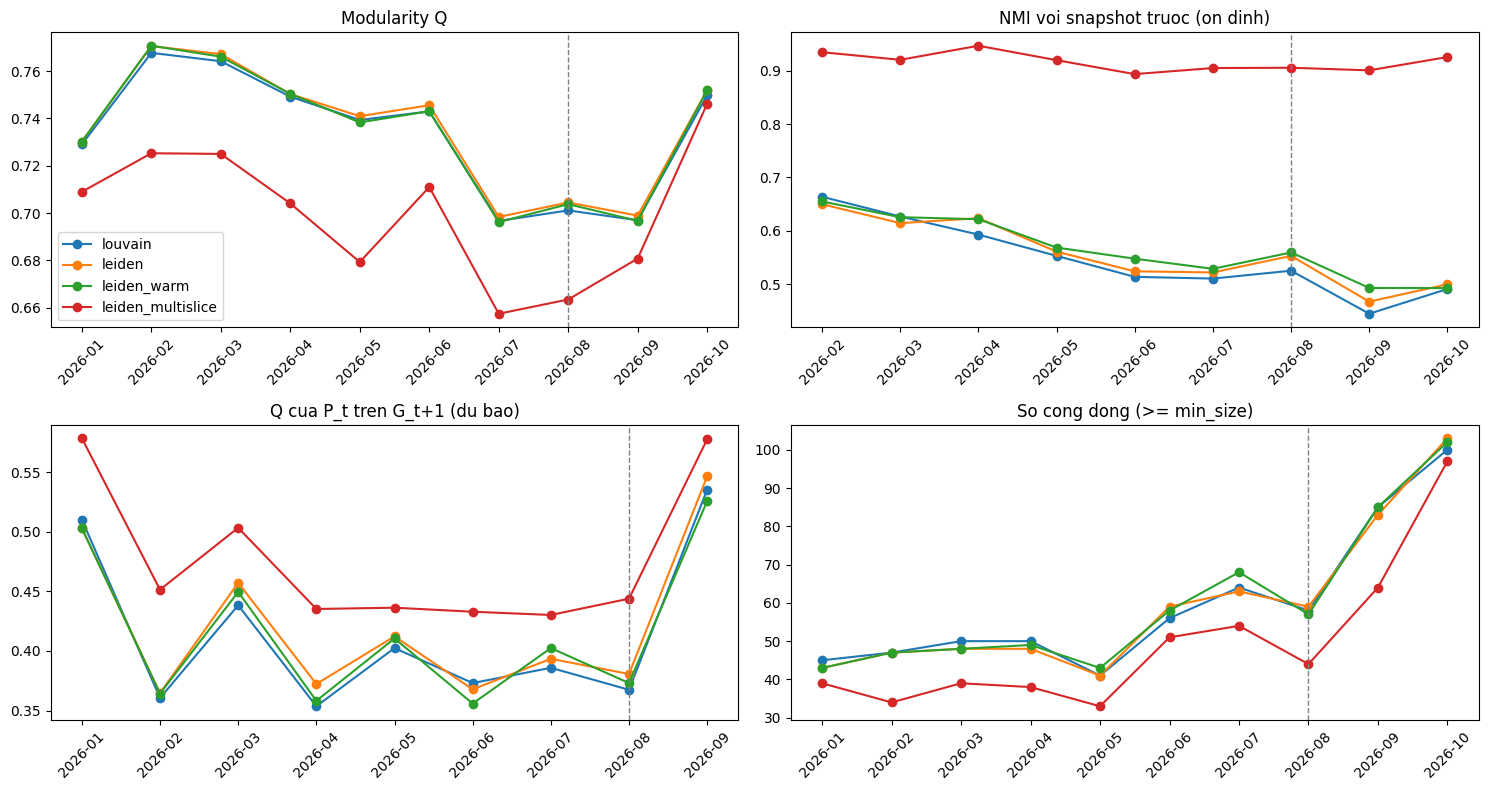

In [7]:
met = pd.read_csv(f'{OUT}/snapshot_metrics.csv')
panels = [('modularity', 'Modularity Q'), ('nmi_prev', 'NMI voi snapshot truoc (on dinh)'),
          ('pred_modularity_next', 'Q cua P_t tren G_t+1 (du bao)'), ('n_communities_tracked', 'So cong dong (>= min_size)')]
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (col, title) in zip(axes.ravel(), panels):
    for m, d in met.groupby('method', sort=False):
        ax.plot(d['snapshot'], d[col], marker='o', label=m)
    split_at = met[met['split'] == 'test']['snapshot'].min()
    ax.axvline(split_at, color='gray', ls='--', lw=1)
    ax.set_title(title); ax.tick_params(axis='x', rotation=45)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/fig_metrics_over_time.png', dpi=150); plt.show()

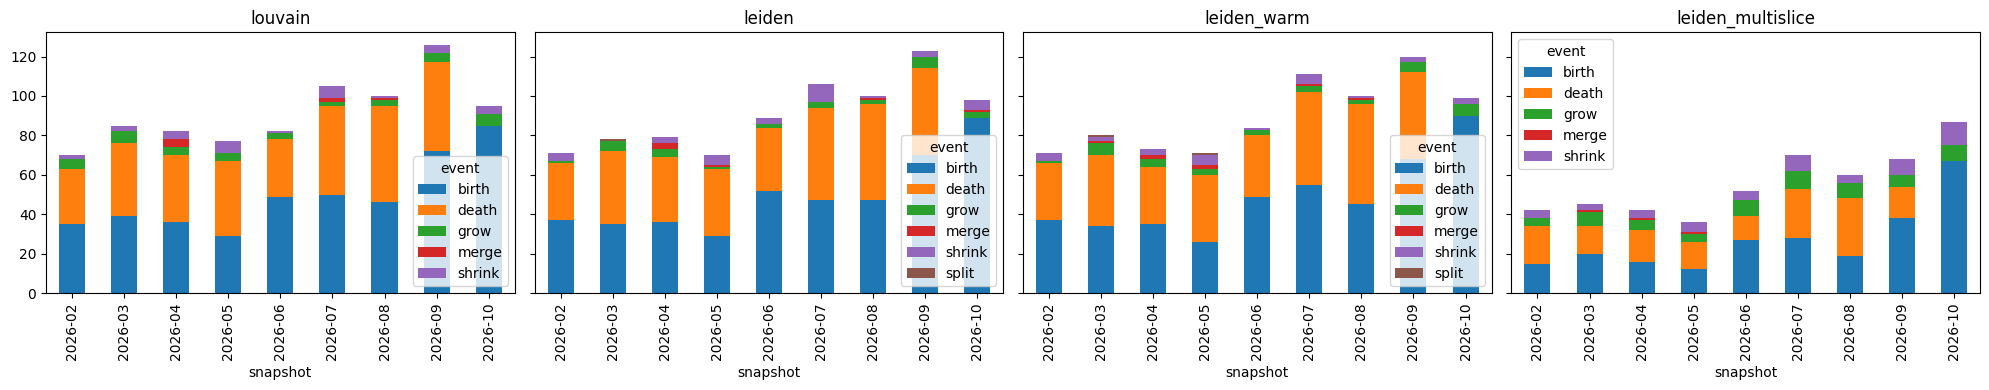

In [8]:
ev = pd.read_csv(f'{OUT}/events.csv')
ev = ev[ev['event'].isin(['birth', 'death', 'merge', 'split', 'grow', 'shrink'])]
methods = ev['method'].unique()
fig, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 4), sharey=True)
for ax, m in zip(axes, methods):
    tab = ev[ev['method'] == m].pivot_table(index='snapshot', columns='event', values='dyn_id', aggfunc='count', fill_value=0)
    tab.plot(kind='bar', stacked=True, ax=ax, title=m)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_events.png', dpi=150); plt.show()

In [9]:
# Su kien lon nhat (theo kich thuoc) cua 2 phuong phap dong
for m in ['leiden_warm', 'leiden_multislice']:
    print('=' * 30, m)
    display(ev[ev['method'] == m].sort_values('size', ascending=False)
            .groupby('event').head(5)[['snapshot', 'event', 'dyn_id', 'size', 'related', 'top_hashtags']])

============================== leiden_warm


,snapshot,event,dyn_id,size,related,top_hashtags
2302,2026-10,grow,326,1408,NaN,xuhuong|viral|xuhuongtiktok|capcut|xh|trending|qdndvn|tiktok|nhachaymoingay|giaitri
2303,2026-10,grow,327,924,NaN,tiktoknews|tintuc|theanh28|phapluat|tiktokgiaitri|tintuc24h|learnontiktok|tinnong|hoccungtiktok|thoisu
2175,2026-09,birth,326,596,NaN,fyp|viral|xuhuongtiktok|capcut|tiktok|nhachaymoingay|nhachottiktok|qdndvn|xhtiktok|edit
2304,2026-10,birth,394,571,NaN,anhhunglietsi|vietnam|congvienlethirieng|saigon|lichsuvietnam|lietsi|tphcm|anhhungdantocvietnam|lichsu|toquocghicong
2176,2026-09,birth,327,477,NaN,tintuc|trending|tiktoknews|tinnong|tintuc24h|theanh28|tiktokgiaitri|truonggiang|2ngay1dem|antoangiaothong
2177,2026-09,grow,227,401,NaN,vietnam|saigon|lichsu|lichsuvietnam|vietnamese|saoviet|viettel|hochiminh|tinquocte|viraltiktok
1984,2026-07,merge,151,335,177.0,xuhuong|viral|xuhuongtiktok|tintuc|trending|tiktoknews|viralvideo|giaitri|tinnong|tiktok
2305,2026-10,birth,395,326,NaN,2ngay1dem|datvietvac|hieuthuhai|2ngay1demmua5|congb|toiyeutoquoctoi|casimatna2026|truonggiang|leduongbaolam|themaske...
2306,2026-10,shrink,6,324,NaN,mukbang|asmr|ancungtiktok|fypシ|fypシ゚viral|reviewanngon|mukbangeatingshow|food|eating|foodie
2178,2026-09,grow,181,298,NaN,xuhuong|xh|thinhhanh|nhachotiktok|tinhhasayhi|datvietvac|muzik4soul|nhachaytiktok|nhacvaoloira|tamtrang


============================== leiden_multislice


,snapshot,event,dyn_id,size,related,top_hashtags
2844,2026-10,grow,3,1313,NaN,xuhuong|viral|xuhuongtiktok|capcut|xh|trending|qdndvn|tiktok|nhachaymoingay|giaitri
2845,2026-10,grow,9,343,NaN,2ngay1dem|datvietvac|hieuthuhai|2ngay1demmua5|congb|toiyeutoquoctoi|casimatna2026|truonggiang|leduongbaolam|themaske...
2596,2026-06,grow,3,281,NaN,xuhuong|fyp|viral|capcut|trending|viralvideo|nhachaymoingay|qdndvn|trend|music
2650,2026-07,grow,6,255,NaN,fyp|mukbang|foryou|asmr|foryoupage|fypシ|fypシ゚viral|beautyqueen|food|ancungtiktok
2763,2026-09,grow,57,231,NaN,xuhuong|xh|thinhhanh|nhachotiktok|tinhhasayhi|datvietvac|muzik4soul|nhachaytiktok|nhacvaoloira|tamtrang
2846,2026-10,shrink,158,164,NaN,game|anime|animefyp|travel|animeedit|freefire|mobilelegends|chainsawman|cs2|mexico
2848,2026-10,shrink,2,159,NaN,games|gaming|usa|roblox|videogames|videogame|gamer|gamergril|usa🇺🇸|gameplay
2765,2026-09,shrink,9,151,NaN,truonggiang|2ngay1dem|showbiz|drama|toiyeutoquoctoi|fyb|hieuthuhai|leduongbaolam|nhaphuong|showbizsohot
2651,2026-07,shrink,4,146,NaN,vietnam|dalat|saigon|dalatreview|dalattrip|dulichdalat|hochiminh|saigonnightlife|vietnamtravel|chill
2767,2026-09,shrink,7,87,NaN,vingroup|fpt|vinfast|chinhsach|phamnhatvuong|dinhhuongnghenghiep|topcomments|xedien|bds|congnhan


In [10]:
# Cong dong dong song lau nhat (leiden_multislice)
tl = pd.read_csv(f'{OUT}/community_timeline.csv')
t = tl[tl['method'] == 'leiden_multislice']
life = t.groupby('dyn_id')['t'].nunique().sort_values(ascending=False)
for d in life.index[:8]:
    print(f'\n--- dyn_id={d}, song {life[d]} snapshot')
    display(t[t['dyn_id'] == d][['snapshot', 'size', 'share', 'event', 'jaccard', 'top_hashtags']])


--- dyn_id=4, song 10 snapshot


,snapshot,size,share,event,jaccard,top_hashtags
1794,2026-01,77,0.068262,initial,NaN,vietnam|saigon|dalat|hochiminh|travel|hochiminhcity|vietnamtravel|caubason|food|hcmc
1833,2026-02,79,0.082723,continue,1.000000,vietnam|dalat|saigon|hochiminhcity|vietnamtravel|travel|chamdidaudo|hanoi|vietnamculture|vlog
1865,2026-03,96,0.081218,continue,1.000000,vietnam|dalat|saigon|travel|vietnamtravel|hochiminhcity|chill|buivien|hochiminh|dulich
1904,2026-04,155,0.103196,grow,0.965517,vietnam|dalat|saigon|chill|travel|hochiminhcity|dulichvietnam|hochiminh|vietnamtravel|cinematic
1941,2026-05,147,0.109701,continue,1.000000,vietnam|saigon|dalat|hochiminhcity|travel|mariokart|vietnamtravel|dalattrip|cafedalat|caonguyenhoadalat
1975,2026-06,161,0.095492,continue,1.000000,vietnam|dalat|saigon|dalatreview|chill|dalatstory|vietnamtravel|dalattrip|hochiminh|hochiminhcity
2028,2026-07,146,0.061139,shrink,0.980000,vietnam|dalat|saigon|dalatreview|dalattrip|dulichdalat|hochiminh|saigonnightlife|vietnamtravel|chill
2086,2026-08,82,0.032220,shrink,0.794118,dalat|dalatreview|dalatcoffee|dulich|thetown|canhdepdalat|chuoi|dalatangi|dalatdidau|happyhilldalat
2131,2026-09,124,0.029836,continue,0.972973,dalat|chill|reviewdalat|dalatdidau|dalatreview|dalatstory|happyhilldalat|batdongsandalat|canhdepdalat|bardalat
2194,2026-10,160,0.024895,continue,0.978261,dalat|dulichdalat|reviewdalat|dalattrip|sanmaydalat|chill|dalatdiary|flypシ|sanmay|canhdepdalat



--- dyn_id=3, song 10 snapshot


,snapshot,size,share,event,jaccard,top_hashtags
1793,2026-01,79,0.070035,initial,NaN,capcut|qdndvn|music|tiktokviral|nhachaymoingay|quandoinhandanvietnam|thinhhanh|quandoi|viralvideo|capcut_edit
1830,2026-02,82,0.085864,continue,0.920000,capcut|viralvideo|foryou|qdndvn|vietsubdouyin|hoạthìnhtrungquốc|动漫推荐|nhachaymoingay|tiktokviral|views
1863,2026-03,143,0.120981,grow,0.833333,xuhuong|xuhuongtiktok|tiktok|trending|capcut|qdndvn|viralvideo|nhachaymoingay|quandoinhandanvietnam|foryou
1902,2026-04,171,0.113848,continue,0.929825,xuhuong|xuhuongtiktok|viralvideo|capcut|trending|foryou|qdndvn|tiktok|nhachaymoingay|quandoinhandanvietnam
1942,2026-05,142,0.105970,continue,0.864407,capcut|tiktok|qdndvn|viralvideo|nhachaymoingay|quandoinhandanvietnam|videoviral|nhacremix|qdndvn🇻🇳|xhtiktok
1973,2026-06,281,0.166667,grow,0.800000,xuhuong|fyp|viral|capcut|trending|viralvideo|nhachaymoingay|qdndvn|trend|music
2024,2026-07,395,0.165410,continue,0.877358,xuhuong|viral|capcut|xuhuongtiktok|xh|trending|viralvideo|nhachaymoingay|tiktok|funny
2078,2026-08,441,0.173281,continue,0.882759,xuhuong|fyp|viral|capcut|trending|qdndvn|trend|nhachaymoingay|tiktok|nhacremix
2122,2026-09,656,0.157844,continue,0.864407,fyp|viral|xuhuongtiktok|trending|capcut|tiktok|nhachaymoingay|nhachottiktok|qdndvn|xhtiktok
2186,2026-10,1313,0.204294,grow,0.908772,xuhuong|viral|xuhuongtiktok|capcut|xh|trending|qdndvn|tiktok|nhachaymoingay|giaitri



--- dyn_id=17, song 10 snapshot


...

,snapshot,size,share,event,jaccard,top_hashtags
1792,2026-01,89,0.078901,initial,NaN,fyp|tiktoknews|learnontiktok|tintuc24h|tintucquocte|foryou|tamlyhoc|suthattamly|tamly|tinnong24h
1832,2026-02,79,0.082723,continue,0.666667,fyp|tiktoknews|tintuc24h|tintuc|usa|game|tiktokgiaitri|tintucquocte|tinnong|roblox
1866,2026-03,82,0.069374,continue,0.736842,fyp|viral|tiktoknews|tintuc24h|usa|tinnong|game|gaming|lifeatvng|gamerforgamer
1905,2026-04,105,0.069907,continue,0.882353,fyp|viral|tiktoknews|tintuc24h|usa|tintucquocte|games|challenge|family|ptfs
1943,2026-05,140,0.104478,grow,0.793103,fyp|viral|foryou|roblox|games|fyppppppppppppppppppppppp|game|vng|gaming|trend
1980,2026-06,51,0.030249,shrink,0.727273,robloxvng|edit|game|playtogether|vng|friends|games|gaming|roblox|filter
2029,2026-07,122,0.051089,grow,0.904762,roblox|robloxvng|vng|robloxfyp|edit|gaming|playtogether|robloxvn|game|games
2083,2026-08,118,0.046365,continue,0.931034,vng|roblox|game|ptfs|robloxvng|playtogether|filter|games|tiktokgame|cargame
2128,2026-09,158,0.038017,continue,0.936170,robloxvng|game|games|robloxgames|ptfs|fun|gamingontiktok|vng|alightmotion|androidgames
2196,2026-10,159,0.024739,shrink,0.790698,games|gaming|usa|roblox|videogames|videogame|gamer|gamergril|usa🇺🇸|gameplay



--- dyn_id=1, song 10 snapshot


,snapshot,size,share,event,jaccard,top_hashtags
1791,2026-01,106,0.093972,initial,NaN,tintuc|giaothong|csgt|tinnong|luatgiaothong|antoangiaothong|thoisu|tinvietnews24h|17network|phapluat
1831,2026-02,82,0.085864,continue,0.857143,haihuoc|giaoduc|phapluatxahoi|plxhvn|xahoi|csgt|giaothong|phapluat|drama|giadinh
1864,2026-03,132,0.111675,grow,0.868421,tintuc|giaothong|phapluatxahoi|plxhvn|haihuoc|giaoduc|csgt|luatgiaothong|kinhte|laixeantoan
1903,2026-04,162,0.107856,continue,0.898305,tintuc|giaothong|viraltiktok|csgt|phapluat|antoangiaothong|haihuoc|tinnong|phapluatxahoi|plxhvn
1940,2026-05,169,0.126119,continue,0.833333,xuhuong|trending|xuhuongtiktok|tiktoknews|tintuc|phapluat|phapluatxahoi|plxhvn|doisong|shorts
1974,2026-06,175,0.103796,continue,0.857143,tintuc|tiktoknews|shorts|csgt|phapluatxahoi|plxhvn|tintuc24h|haihuoc|phapluat|doisong
2025,2026-07,275,0.115159,continue,0.826531,tintuc|tiktoknews|learnontiktok|phapluatxahoi|plxhvn|phapluat|shorts|giaitri|tinnong|giaoduc
2079,2026-08,283,0.111198,continue,0.899160,tintuc|learnontiktok|tiktoknews|phapluat|tintuc24h|giaoduc|tinnong|antoangiaothong|giaothong|hoccungtiktok
2123,2026-09,527,0.126805,continue,0.880000,tintuc|tiktoknews|learnontiktok|phapluat|tinnong|tintuc24h|hoccungtiktok|theanh28|tiktokgiaitri|xahoi
2187,2026-10,873,0.135833,continue,0.950382,tiktoknews|tintuc|theanh28|phapluat|tiktokgiaitri|tintuc24h|learnontiktok|tinnong|hoccungtiktok|thoisu



--- dyn_id=0, song 10 snapshot


,snapshot,size,share,event,jaccard,top_hashtags
1790,2026-01,143,0.126773,initial,NaN,xuhuong|viral|trending|xuhuongtiktok|xh|runningman|tonhoasen|vng|tiktokgiaitri|tiktok
1829,2026-02,95,0.099476,continue,0.923077,xuhuong|viral|trending|xh|xuhuongtiktok|tetgiulua|review|reviewphim|2ngay1dem|tiktok
1874,2026-03,38,0.032149,shrink,0.444444,review|reviewphim|movie|vng|foryoupage|news|codeplaytogether|costream|cuthitra|cutravtv
1914,2026-04,45,0.029960,continue,0.750000,reviewphim|review|phimhay|sportsontiktok|sports|thethao247|vutru|film|hanhtinh|phimhaymoingay
1951,2026-05,28,0.020896,shrink,1.000000,reviewphim|phimhaymoingay|phimhay|review|dbgnetwork|readyornot|cartonvn2|cotrang|doraemon|doraemondulichvietnam
1991,2026-06,19,0.011269,shrink,1.000000,reviewphim|phimhay|phimhaymoingay|review|reviewphimhay|auaudouyin|capcutfor|doraemon|hanvude|incendies
2030,2026-07,92,0.038526,grow,0.777778,phimhay|reviewphim|phimhoathinh|phimhaymoingay|animation|hoathinh|anime|foryoupage❤️❤️|hoathinhtrungquoc|kinhdi
2087,2026-08,77,0.030255,continue,0.920000,reviewphim|phimhay|phimhaymoingay|phimhoathinh|anime|drama|hoathinh|phimtrungquoc|phimngan|reviewphimhay
2130,2026-09,127,0.030558,continue,0.774194,reviewphim|phimhay|phimngan|review|traibuonnguoi|phimhaymoingay|phimchieurap|phimtrungquoc|reviewphimhay|hoathinh
2191,2026-10,243,0.037809,continue,0.967213,fyp|reviewphim|phimhay|foryou|phimtrungquoc|reviewphimhay|review|phimhaymoingay|mereviewphim|1


## 3. (Tuy chon) Kiem tra do nhay - can bang so video moi snapshot
Du lieu crawl lech ve thang gan day (thang 10 nhieu video hon thang 1 ~10 lan). Chay lai voi toi da 450 video/snapshot de kiem tra ket luan co phu thuoc vao kich thuoc mau khong.

In [13]:
!zip -r /kaggle/working/stage3_output.zip /kaggle/working/stage3_output

updating: kaggle/working/stage3_output/ (stored 0%)
updating: kaggle/working/stage3_output/tuning_result.json (deflated 43%)
updating: kaggle/working/stage3_output/tuning.csv (deflated 51%)
  adding: kaggle/working/stage3_output/fig_metrics_over_time.png (deflated 6%)
  adding: kaggle/working/stage3_output/run_config.json (deflated 56%)
  adding: kaggle/working/stage3_output/fig_events.png (deflated 25%)
  adding: kaggle/working/stage3_output/method_comparison.csv (deflated 50%)
  adding: kaggle/working/stage3_output/community_timeline.csv (deflated 66%)
  adding: kaggle/working/stage3_output/snapshots.csv (deflated 49%)
  adding: kaggle/working/stage3_output/partitions.csv (deflated 80%)
  adding: kaggle/working/stage3_output/snapshot_metrics.csv (deflated 57%)
  adding: kaggle/working/stage3_output/events.csv (deflated 71%)


In [11]:
import json
best = json.load(open(f'{OUT}/tuning_result.json'))
OUT_B = f'{WORK}/stage3_output_balanced'
G, W = best['gamma'], best['omega']
!python stage3_dynamic_communities.py run --input {DATA} --output {OUT_B} --max-videos 450 --gamma {G} --omega {W}
pd.read_csv(f'{OUT_B}/method_comparison.csv').query("split == 'all'").round(4)

[13:07:04] [EVAL] 10 snapshot, gamma=1.0, omega=5.0, train=7, test=3
[13:07:05]   louvain            Q=0.7267 NMI_prev=0.5813 Q_next=0.3815 dyn_comms=307 (0.2s)
[13:07:12]   leiden             Q=0.7284 NMI_prev=0.5809 Q_next=0.3797 dyn_comms=318 (7.2s)
[13:07:21]   leiden_warm        Q=0.7272 NMI_prev=0.5764 Q_next=0.3811 dyn_comms=320 (8.3s)
[13:09:26]   leiden_multislice  Q=0.6904 NMI_prev=0.9254 Q_next=0.4499 dyn_comms=178 (124.8s)
[13:09:26] [EVAL] Da luu ket qua vao /kaggle/working/stage3_output_balanced
[13:09:26] Hoan tat sau 142s


,method,split,n_snapshots,modularity,coverage,mean_conductance,n_communities_tracked,nmi_prev,ari_prev,pred_modularity_next,seed_stability_nmi,n_birth,n_death,n_merge,n_split,n_grow,n_shrink,n_dynamic_communities,mean_lifetime,frac_lifetime_ge3,seconds
0,louvain,all,10,0.7267,0.8572,0.0652,41.6,0.5813,0.2364,0.3815,0.9156,263,228,14,2,40,29,307.0,1.3550,0.0879,0.2
3,leiden,all,10,0.7284,0.8576,0.0653,42.3,0.5809,0.2385,0.3797,0.9333,271,239,14,3,32,27,318.0,1.3302,0.0692,7.2
6,leiden_warm,all,10,0.7272,0.8588,0.0626,41.6,0.5764,0.2358,0.3811,0.9126,273,243,13,3,32,22,320.0,1.3000,0.0688,8.3
9,leiden_multislice,all,10,0.6904,0.8207,0.1271,37.9,0.9254,0.8414,0.4499,0.8627,134,121,4,0,61,53,178.0,2.1292,0.1461,124.8


In [12]:
# Nen ket qua de tai ve (Output -> stage3_results.zip)
shutil.make_archive(f'{WORK}/stage3_results', 'zip', WORK, 'stage3_output')
if os.path.exists(f'{WORK}/stage3_output_balanced'):
    shutil.make_archive(f'{WORK}/stage3_results_balanced', 'zip', WORK, 'stage3_output_balanced')
print(os.listdir(WORK))

['stage3_results_balanced.zip', 'stage3_dynamic_communities.py', 'tittokSNA28', 'stage3_output', 'stage3_results.zip', 'stage3_output_balanced', 'stage3_output.zip', '.virtual_documents']
